In [ ]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
#from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm

In [ ]:
# Cargar el dataset Boston Housing
df = pd.read_csv("https://raw.githubusercontent.com/omarmendoza564/datos/main/datos/BostonHousing.csv")
df

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


# Boston House Prices - Descripción de Variables

- **crim**: Tasa de criminalidad per cápita por ciudad.
- **zn**: Proporción de terrenos residenciales divididos en zonas de más de 25,000 pies cuadrados.
- **indus**: Proporción de acres de negocios no minoristas por ciudad.
- **chas**: Variable dummy del río Charles; 1 si el tramo limita con el río, 0 en caso contrario.
- **nox**: Concentración de óxidos nítricos en partes por 10 millones.
- **rm**: Número medio de habitaciones por vivienda.
- **age**: Proporción de unidades ocupadas por propietarios construidas antes de 1940.
- **dis**: Distancia ponderada a cinco centros de empleo de Boston.
- **rad**: Índice de accesibilidad a autopistas radiales.
- **tax**: Tasa de impuestos sobre el valor total por $10,000.
- **ptratio**: Ratio alumno-profesor por ciudad.
- **b**: Proporción de personas de raza negra por ciudad.
- **lstat**: Porcentaje de población de bajo estatus.
- **medv**: Valor mediano de las casas ocupadas por propietarios en $1000.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
zn,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
indus,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
chas,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
nox,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
rm,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
age,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
dis,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
rad,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
tax,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


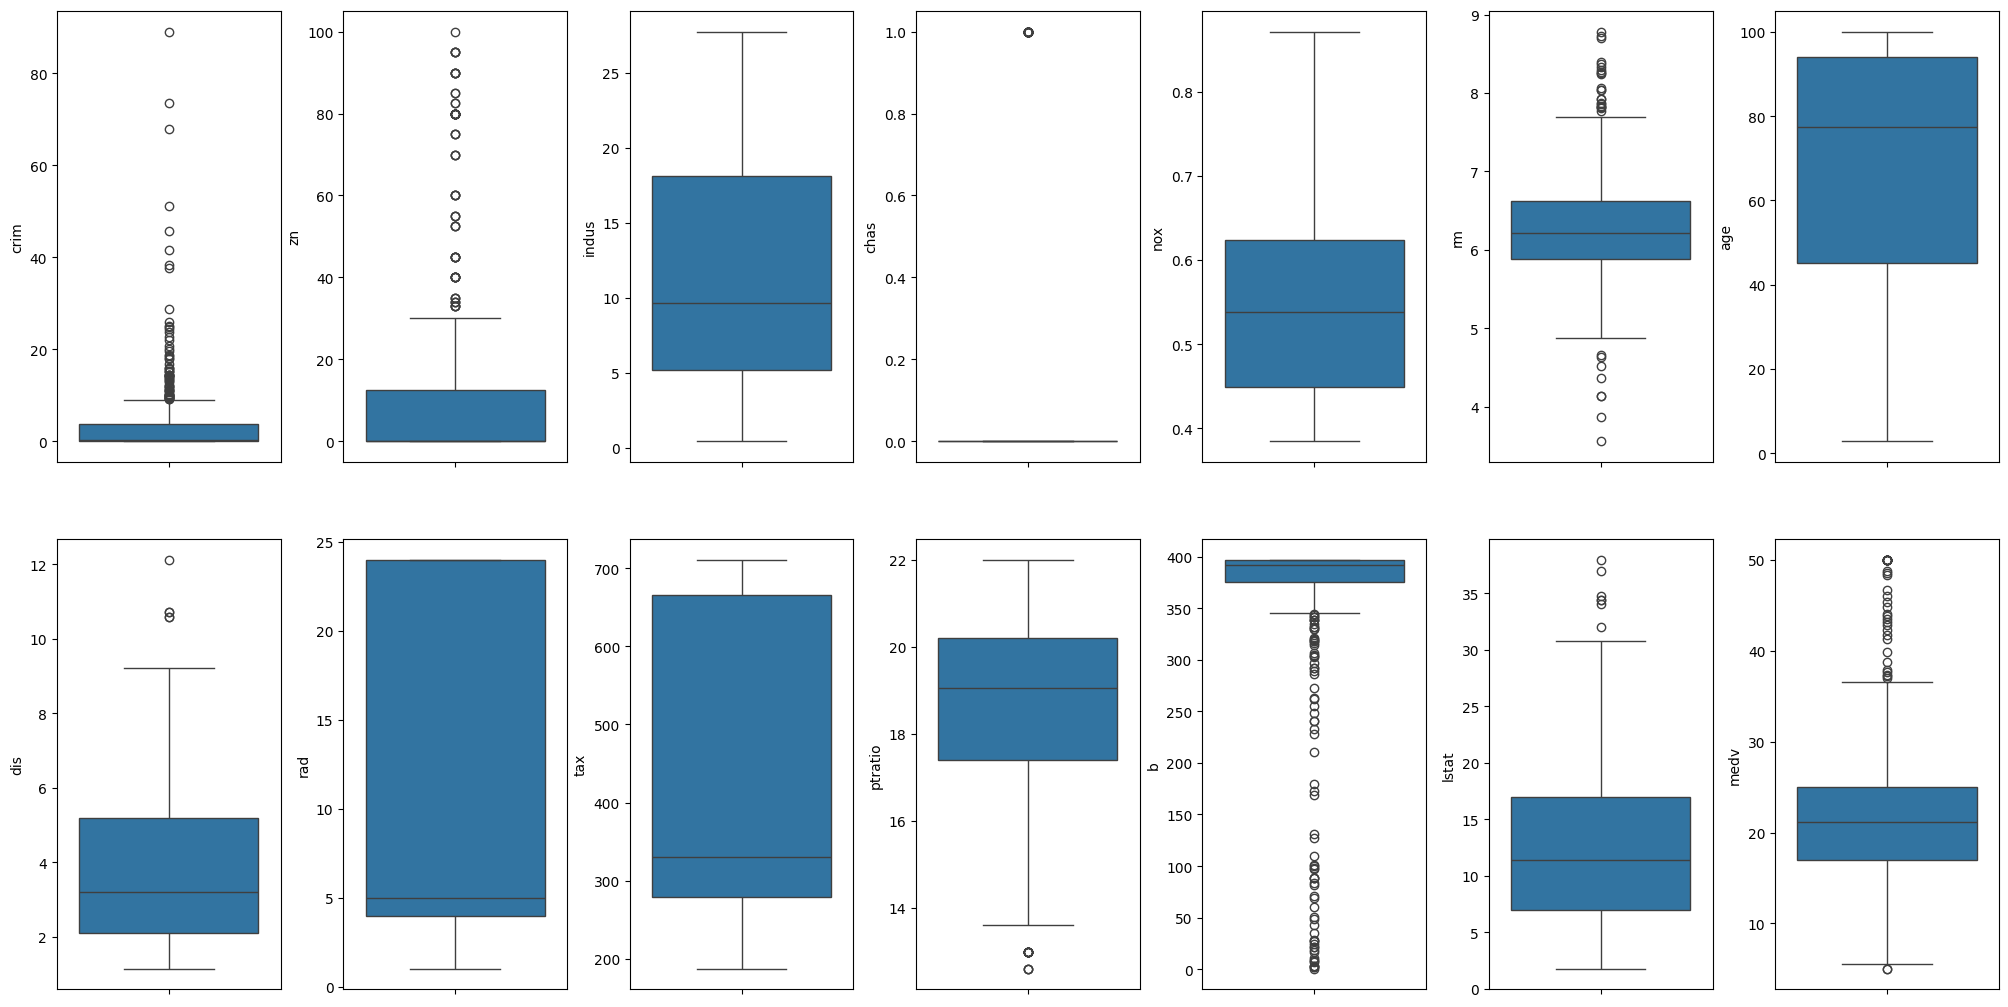

In [ ]:
#Columnas como CRIM, ZN, RM, B parecen tener valores atípicos.
#Veamos el porcentaje de valores atípicos en cada columna.
fig, axs = plt.subplots(ncols=7, nrows=2, figsize=(20, 10))
index = 0
axs = axs.flatten()
for k,v in df.items():
    sns.boxplot(y=k, data=df, ax=axs[index])
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)

* crim (Tasa de criminalidad per cápita por ciudad):
    * Se observan muchos outliers en la parte superior, lo que sugiere que hay áreas con tasas de criminalidad significativamente más altas que la mayoría.
* zn (Proporción de terrenos residenciales divididos en zonas de más de 25,000 pies cuadrados):
    * La mayoría de los valores son cercanos a 0, con algunos outliers en la parte superior, indicando áreas con terrenos más grandes.

* indus (Proporción de acres de negocios no minoristas por ciudad):
    * Distribución más uniforme, con pocos outliers en la parte superior. La mayoría de los valores están concentrados en el rango intercuartílico.

* chas (Charles River dummy variable; 1 si el tramo limita con el río, 0 en caso contrario):
    * Variable mayormente binaria con muy pocos outliers. La mayoría de los valores están en 0.

* nox (Concentración de óxidos nítricos en partes por 10 millones):
    * Distribución bastante concentrada, sin muchos outliers, con la mediana ligeramente por debajo del centro de la caja.

* rm (Número medio de habitaciones por vivienda):
    * Muestra varios outliers en la parte superior e inferior, pero con una distribución más centrada alrededor de la mediana.

* age (Proporción de unidades ocupadas por propietarios construidas antes de 1940):
    * La mayoría de las viviendas son más antiguas (edad elevada), con una distribución que se inclina hacia la parte superior. No hay outliers significativos.

* dis (Distancia ponderada a cinco centros de empleo de Boston):
    * Presenta algunos outliers en la parte superior, con la mayoría de las observaciones concentradas en la mitad inferior del rango.

* rad (Índice de accesibilidad a autopistas radiales):
    * Variable con una distribución que muestra pocos valores en la parte baja y muchos valores agrupados en la parte superior, sin outliers.

* tax (Tasa de impuestos sobre el valor total por $10,000):
    * Similar a rad, tiene una distribución más concentrada en la parte superior, con pocos outliers.

* ptratio (Ratio alumno-profesor por ciudad):
    * Presenta algunos outliers en la parte inferior, pero en general una distribución centrada con la mediana hacia la parte superior.

* b (Proporción de personas de raza negra por ciudad):
    * Contiene muchos outliers en la parte inferior, con una mayoría de valores muy altos, lo que sugiere una gran variabilidad en esta proporción.

* lstat (Porcentaje de población de bajo estatus):
    * Muestra varios outliers en la parte superior, pero la mayoría de los valores están distribuidos de manera relativamente uniforme dentro del rango intercuartílico.

* medv (Valor mediano de las casas ocupadas por propietarios en $1000):
    * Se observan algunos outliers en la parte superior e inferior, pero la distribución está más centrada con una mediana hacia la parte superior de la caja.

In [ ]:
#Correlacion lineal de RM y MEDV usando pearsonr
cc, p_value = pearsonr(df['rm'], df['medv'])
print(f'Correlacion lineal de RM y MEDV: {cc} con un valor p de {p_value}')

Correlacion lineal de RM y MEDV: 0.6953599470715395 con un valor p de 2.487228871007625e-74


La correlación de Pearson mide la relación lineal entre dos variables. Sus valores pueden oscilar entre -1 y 1:

- **1** indica una correlación positiva perfecta.
- **-1** indica una correlación negativa perfecta.
- **0** indica que no hay correlación.

Dado un valor de correlación de Pearson de **0.695** entre `RM` (número medio de habitaciones por vivienda) y `MEDV` (valor medio de viviendas):

1. **Dirección de la relación**: La correlación es positiva, lo que significa que, en general, a medida que `RM` aumenta, `MEDV` también tiende a aumentar y viceversa.

2. **Fuerza de la relación**: El valor 0.695 es relativamente alto, por lo que indica una correlación positiva moderadamente fuerte entre las dos variables. No es una relación perfecta, pero sí es sustancial.

3. **Interpretación**: Esto sugiere que las viviendas con un mayor número de habitaciones (mayor valor de `RM`) tienden a tener un valor medio más alto (mayor `MEDV`). En otras palabras, las viviendas con más habitaciones tienden a ser más caras en este conjunto de datos.

* Correlación Lineal (0.6954):
* La correlación lineal de 0.6954 indica una fuerte relación positiva entre RM y MEDV. Esto significa que, en general, a medida que aumenta el número medio de habitaciones en una vivienda (RM), también aumenta el valor mediano de la casa (MEDV).

Sin embargo, es importante recordar que la correlación no implica causalidad. Mientras que `RM` y `MEDV` están correlacionados, no podemos decir que un mayor número de habitaciones causa un mayor valor de la vivienda sin un análisis más profundo. Puede haber otras variables en juego o factores externos que afecten a ambas variables.

* Valor p (2.4872e-74):

*  El valor p es una medida de la evidencia en contra de la hipótesis nula (que normalmente establece que no hay relación entre las dos variables). Un valor p muy pequeño indica que es extremadamente improbable que la correlación observada haya ocurrido por casualidad.
Interpretación:
* En este caso, el valor p es 2.4872e-74, lo que es esencialmente 0 cuando lo comparas con cualquier nivel de significancia convencional (por ejemplo, 0.05 o 0.01).
*  Esto significa que la probabilidad de observar una correlación tan alta entre RM y MEDV por mera casualidad es prácticamente inexistente.
* Por lo tanto, puedes rechazar con confianza la hipótesis nula y concluir que existe una relación estadísticamente significativa entre el número de habitaciones y el valor mediano de las viviendas.

In [ ]:
#Correlacion de medv contra todas las variables
for c in df.columns:
  cc, p_value = pearsonr(df[c], df['medv'])
  print("*****",40)
  print("Variable:", c)
  print("Coeficiente de correlación de Pearson:", cc)
  print("Valor p:", p_value)

***** 40
Variable: crim
Coeficiente de correlación de Pearson: -0.38830460858681154
Valor p: 1.1739870821943684e-19
***** 40
Variable: zn
Coeficiente de correlación de Pearson: 0.360445342450543
Valor p: 5.713584153081037e-17
***** 40
Variable: indus
Coeficiente de correlación de Pearson: -0.4837251600283729
Valor p: 4.90025998175246e-31
***** 40
Variable: chas
Coeficiente de correlación de Pearson: 0.1752601771902984
Valor p: 7.390623170519845e-05
***** 40
Variable: nox
Coeficiente de correlación de Pearson: -0.4273207723732826
Valor p: 7.065041586253448e-24
***** 40
Variable: rm
Coeficiente de correlación de Pearson: 0.6953599470715395
Valor p: 2.487228871007625e-74
***** 40
Variable: age
Coeficiente de correlación de Pearson: -0.3769545650045963
Valor p: 1.5699822091880626e-18
***** 40
Variable: dis
Coeficiente de correlación de Pearson: 0.24992873408590388
Valor p: 1.2066117273371499e-08
***** 40
Variable: rad
Coeficiente de correlación de Pearson: -0.38162623063977796
Valor p: 5.4

<Axes: >

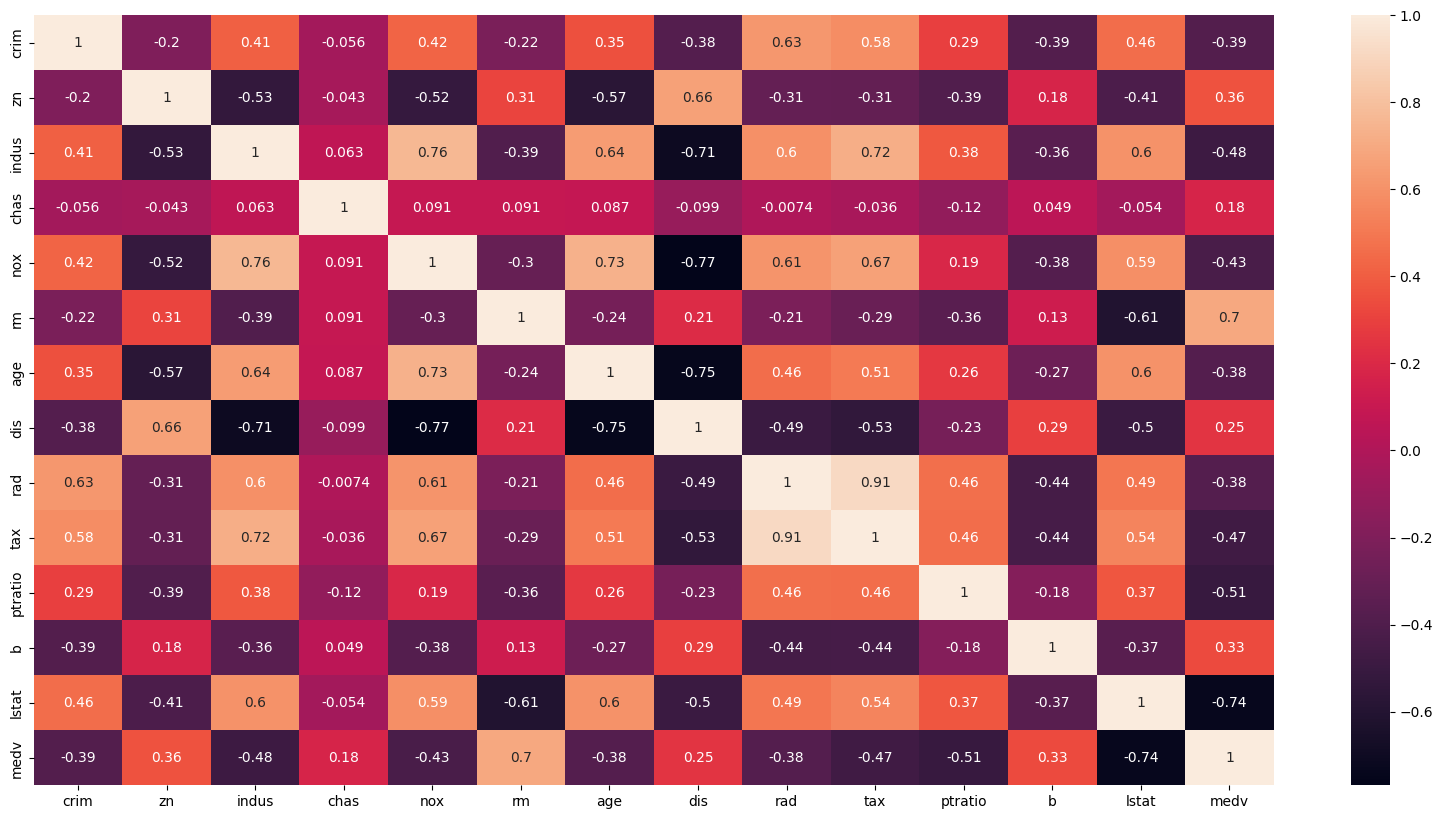

In [ ]:
#Matriz de correlacion
#De la matriz de correlación, vemos que TAX y RAD son características altamente correlacionadas.
# Las columnas LSTAT, INDUS, RM, TAX, NOX, PTRAIO tienen una puntuación de correlación superior a 0,5 con MEDV,
# lo que es una buena indicación de su uso como predictores.
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(), annot=True)

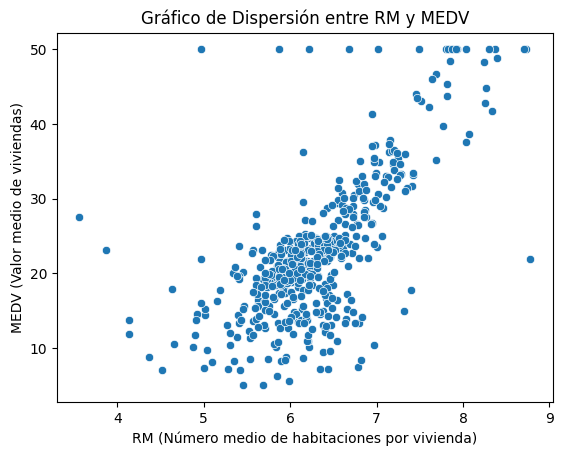

In [ ]:
# Gráfico de dispersión entre RM y MEDV
sns.scatterplot(data = df, x = 'rm', y = 'medv')
plt.title("Gráfico de Dispersión entre RM y MEDV")
plt.xlabel("RM (Número medio de habitaciones por vivienda)")
plt.ylabel("MEDV (Valor medio de viviendas)")
plt.show()

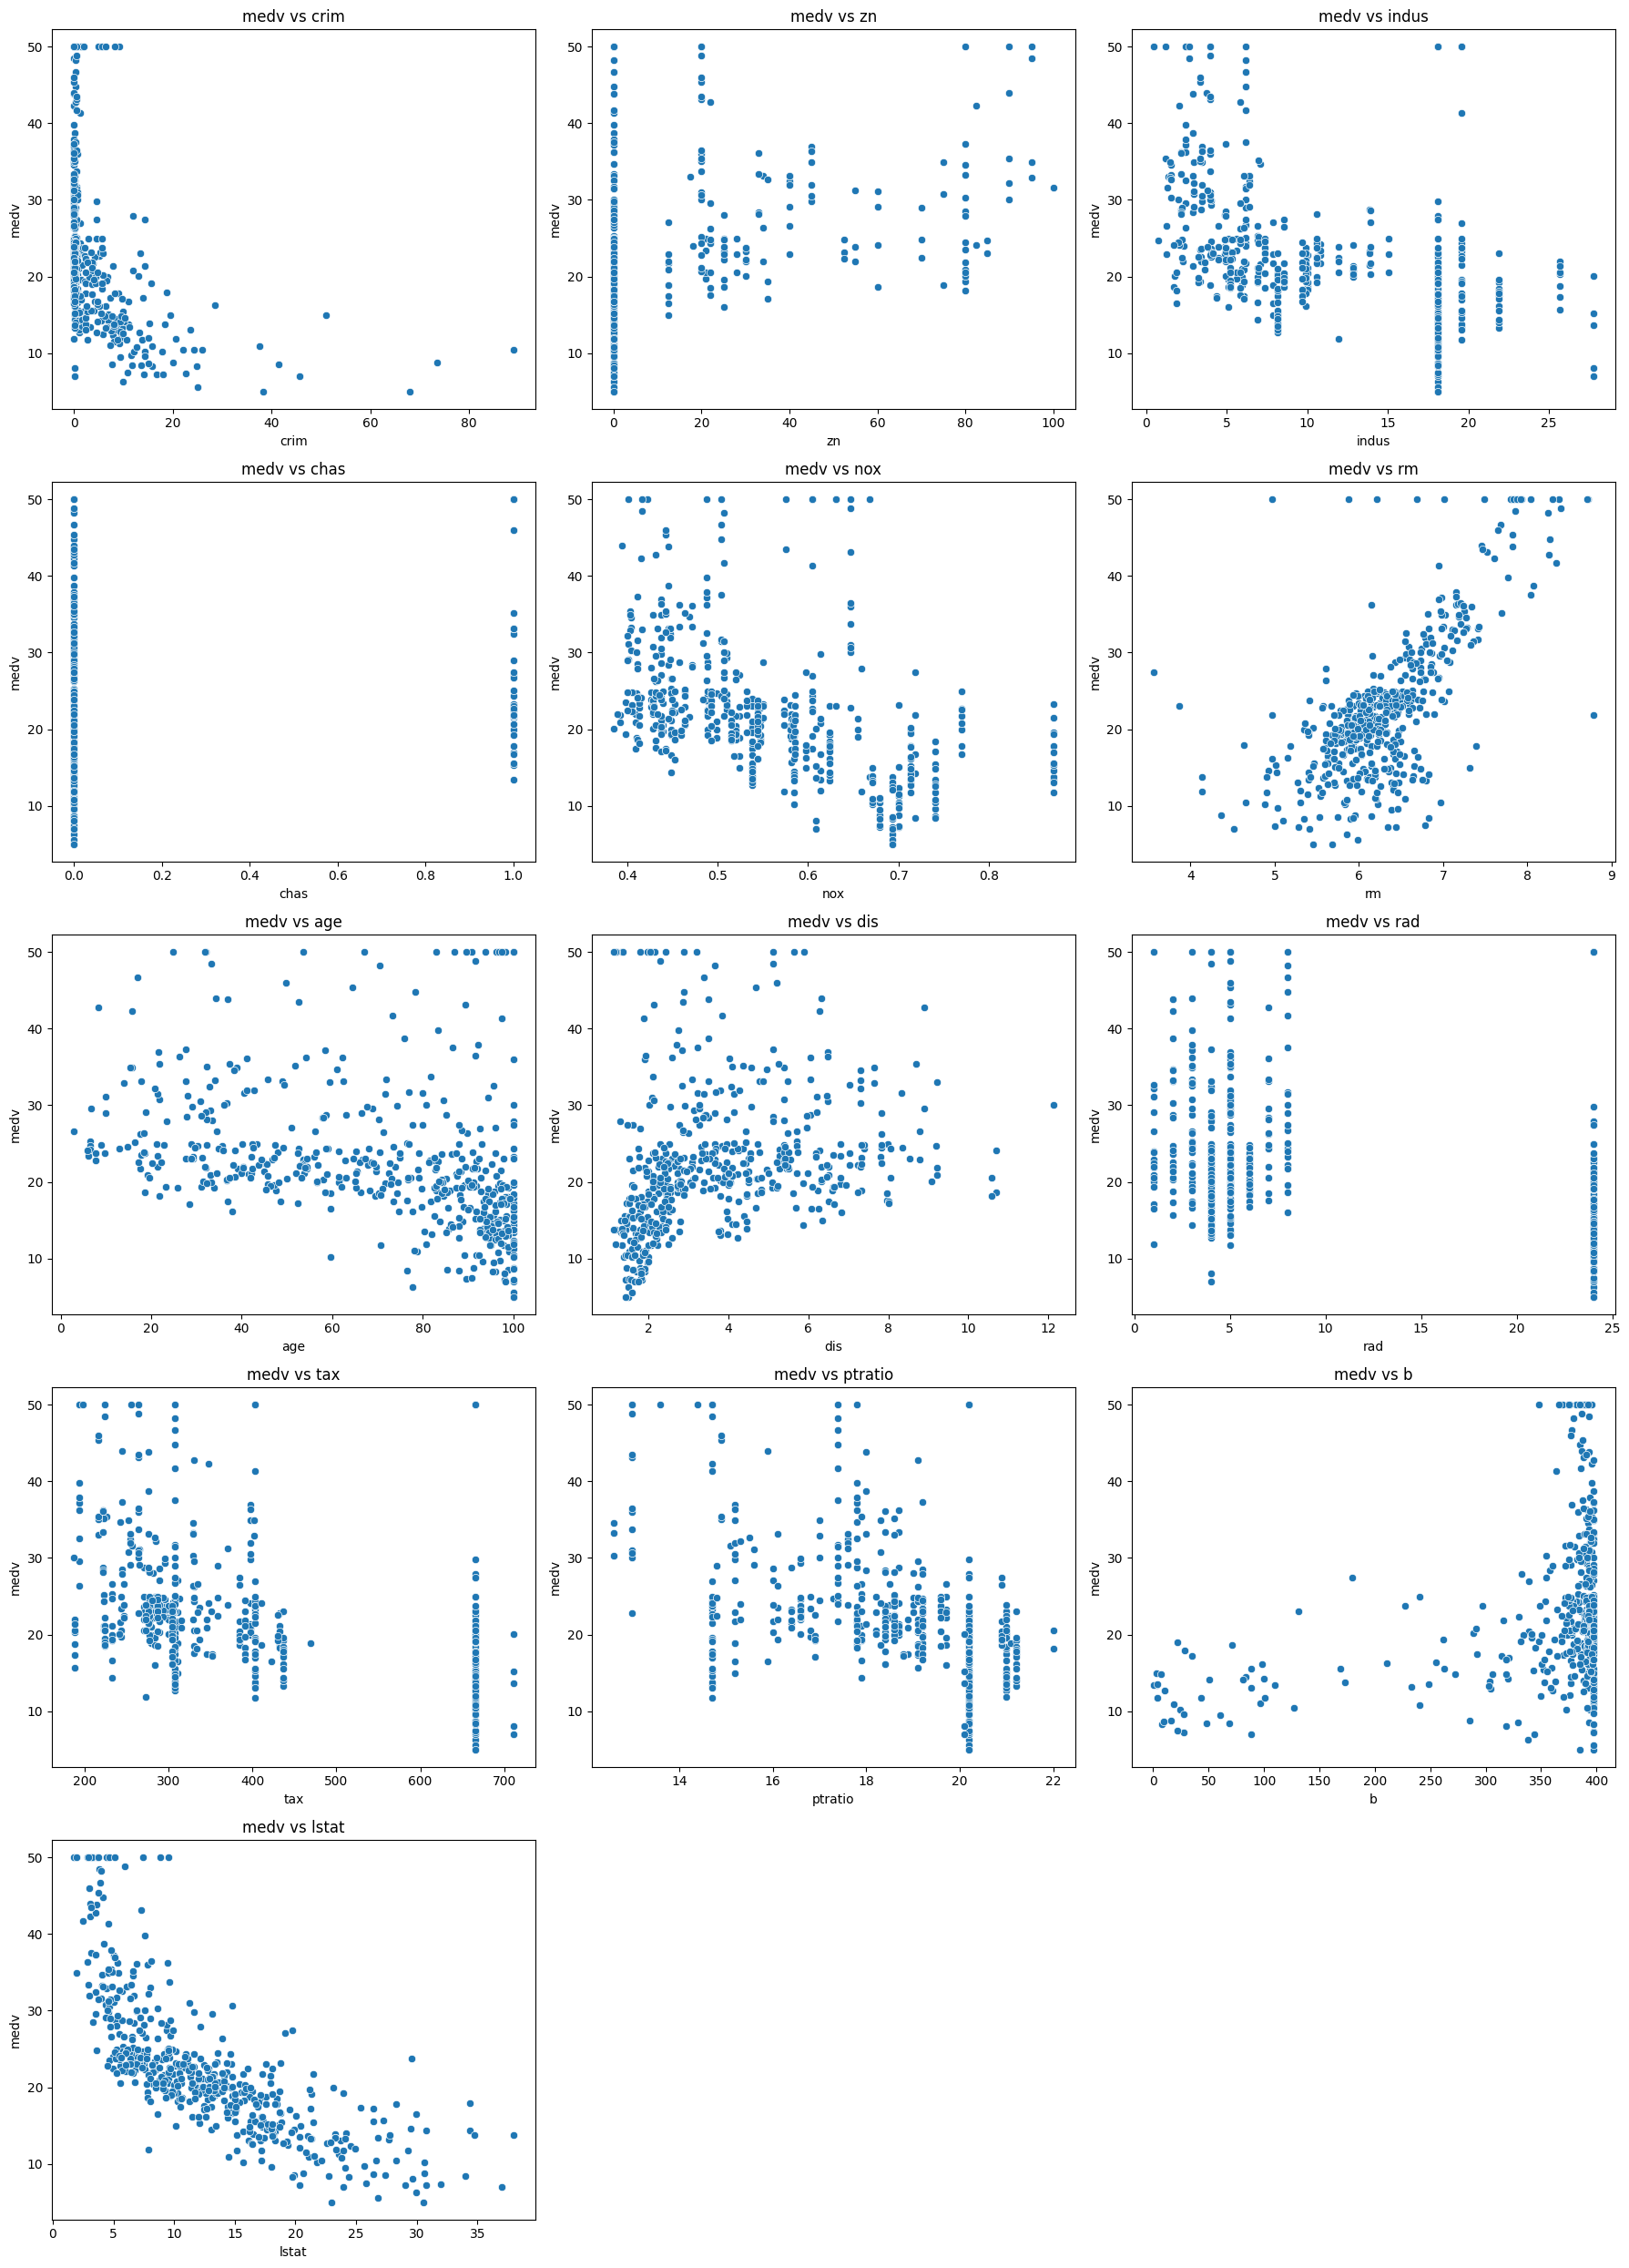

In [ ]:
import math
# Variables a graficar (excepto 'medv')
features = [c for c in df.columns if c != 'medv']
n = len(features)
cols = 3  # 3 gráficas por fila
rows = math.ceil(n / cols)

# Crear subplots
fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()  # Convertir a lista para iterar fácilmente

# Graficar cada variable
for i, c in enumerate(features):
    sns.scatterplot(x=df[c], y=df['medv'], ax=axes[i])
    axes[i].set_title(f"medv vs {c}")
    axes[i].set_xlabel(c)
    axes[i].set_ylabel("medv")

# Quitar ejes vacíos si sobran
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

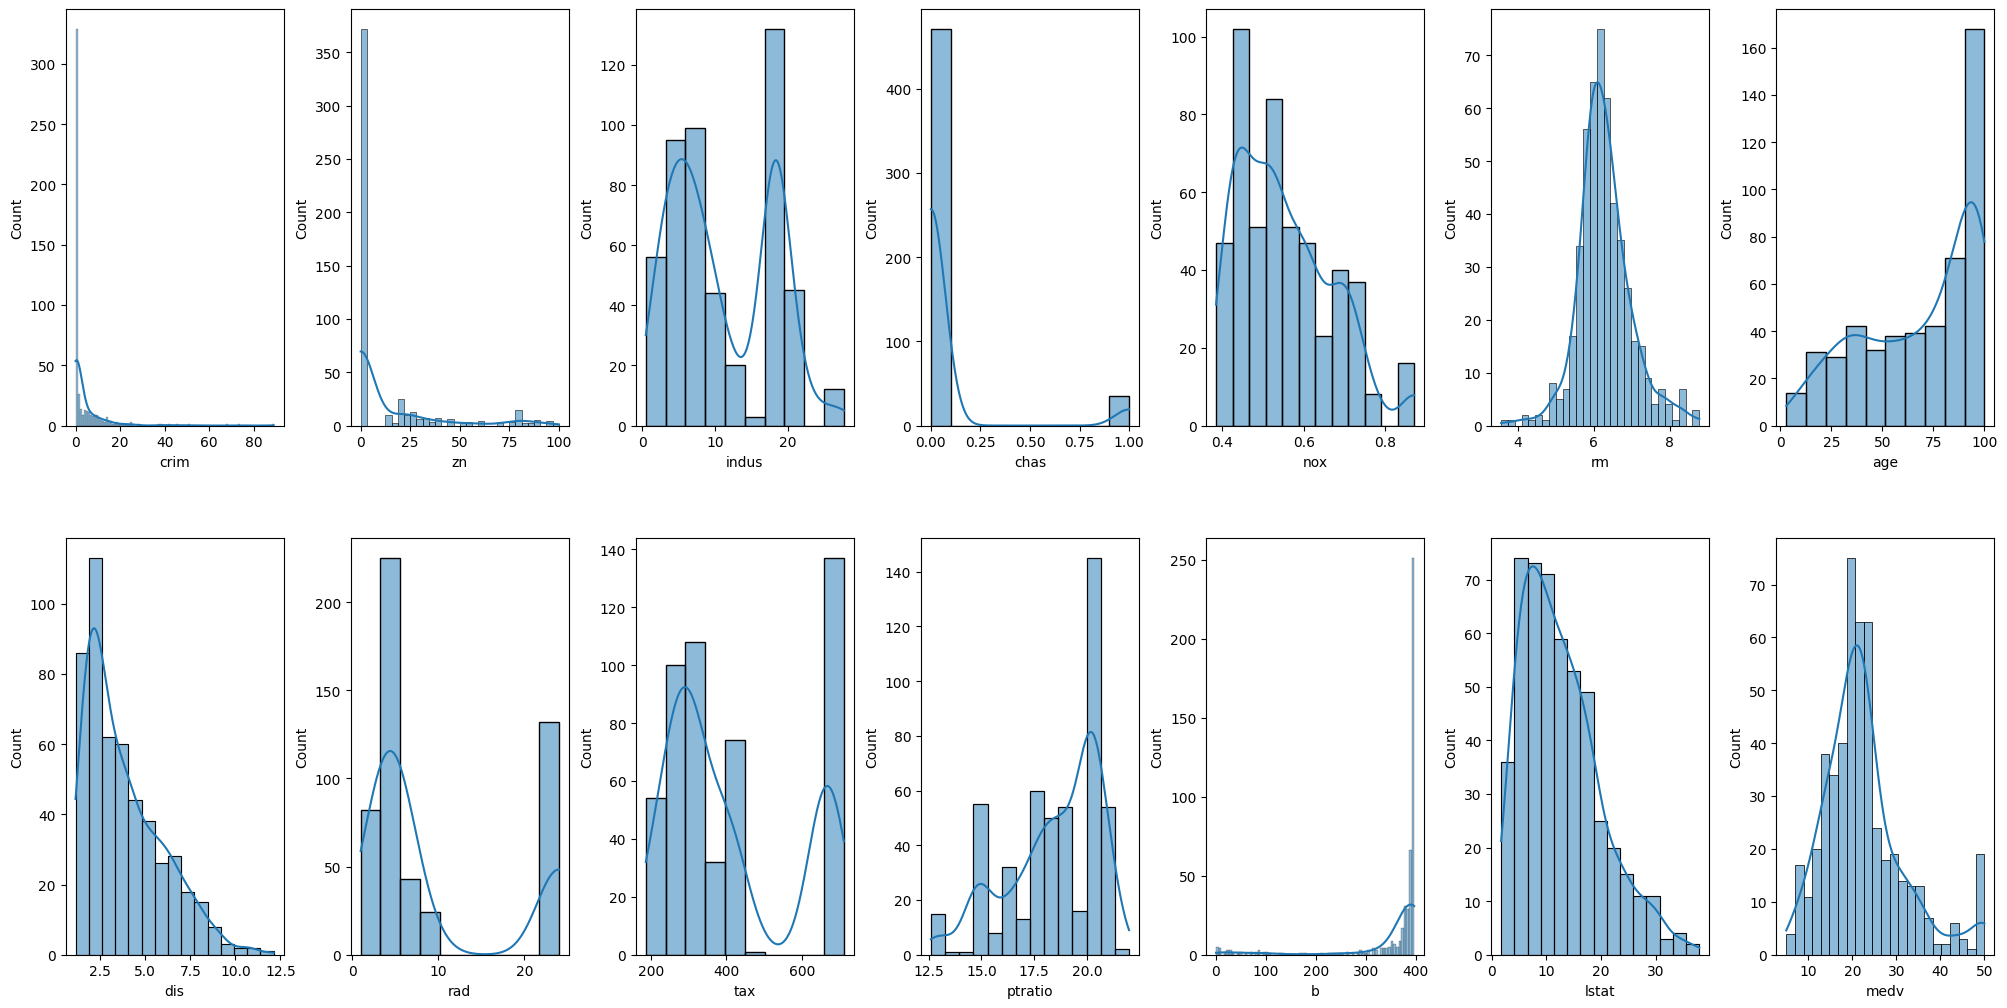

In [ ]:
# Gráfico de la distribución de la variable objetivo MEDV
#sns.distplot(df['MEDV'], bins=30)
#plt.title("Distribución de MEDV")
#plt.show()
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

fig, axs = plt.subplots(ncols=7, nrows=2, figsize=(20, 10))
index = 0
axs = axs.flatten()
for k,v in df.items():
    sns.histplot(v, ax=axs[index], kde=True)
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)

#El histograma también muestra que las columnas CRIM, ZN, B tienen distribuciones muy sesgadas.
#Además, MEDV parece tener una distribución normal (las predicciones)
#Otras columnas parecen tener una distribución de datos normal o bimodelo, excepto CHAS (que es una variable discreta).

In [ ]:
# Dividir los datos en conjuntos de entrenamiento y prueba
X = df.drop('medv', axis=1)  # Características
y = df['medv']               # Variable objetivo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Agregar constante SOLO después de dividir los datos
# Así evitas modificar X completo y mantener las mismas columnas en train y3 test
X_train = sm.add_constant(X_train, has_constant='add')
X_test = sm.add_constant(X_test, has_constant='add')


In [ ]:
print(X_train.shape)
print(X_train.columns)

(404, 14)
Index(['const', 'crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis',
       'rad', 'tax', 'ptratio', 'b', 'lstat'],
      dtype='object')


In [ ]:
print(X_test.shape)
print(X_test.columns)

(102, 14)
Index(['const', 'crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis',
       'rad', 'tax', 'ptratio', 'b', 'lstat'],
      dtype='object')


In [ ]:
# Crear una copia temporal de X_train para la eliminación hacia atrás
X_selected = X_train.copy()

# Agregar constante
#X = sm.add_constant(X, has_constant='add')

# Umbral de significancia (típicamente 0.05)
significance_level = 0.05

# Proceso iterativo de eliminación hacia atrás
while True:
    # Se ajusta un modelo de regresión lineal OLS (Ordinary Least Squares)
    #Busca una relación lineal entre una variable dependiente y y una o más variables independientes X.
    # Minimiza el error cuadrático total
    model = sm.OLS(y_train, X_selected).fit()
    p_values = model.pvalues
    max_pval = p_values.max()
    if max_pval > significance_level:
        excluded_variable = p_values.idxmax()
        print(f"Eliminando: {excluded_variable} (p={max_pval:.4f})")
        X_selected = X_selected.drop(columns=[excluded_variable])
    else:
        break

# Resultado final
print("\nResumen del modelo final:")
print(model.summary())


Eliminando: age (p=0.6658)
Eliminando: indus (p=0.5570)
Eliminando: zn (p=0.0614)

Resumen del modelo final:
                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.742
Method:                 Least Squares   F-statistic:                     116.8
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          3.85e-111
Time:                        17:43:26   Log-Likelihood:                -1196.4
No. Observations:                 404   AIC:                             2415.
Df Residuals:                     393   BIC:                             2459.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------

📊 Resumen e interpretación del modelo de regresión (versión para estudiantes)

Hemos construido un modelo de regresión lineal múltiple para predecir el valor medio de las viviendas (medv) usando varias variables del conjunto de datos de Boston.

🔎 Resultados clave:

* R-cuadrado ajustado: 0.735
* El modelo explica aproximadamente el 73.5% de la variación en el precio de las viviendas. Es un buen nivel de ajuste.

Eliminación de variables
Se eliminaron dos variables (age e indus) porque no eran significativas (su valor p era mayor a 0.05).

Variables importantes
Todas las variables que quedaron en el modelo tienen un valor p menor a 0.05, lo que significa que sí ayudan a predecir el valor de las casas.
Las más influyentes son:

rm: A más habitaciones, mayor precio (relación positiva).

lstat: A mayor porcentaje de personas con bajo nivel socioeconómico, menor precio (relación negativa).

nox: A mayor contaminación, menor precio.

Cuidado con la multicolinealidad
El modelo muestra señales de que algunas variables podrían estar correlacionadas entre sí. Se puede investigar más adelante con otras herramientas (como VIF).

✅ Conclusión:

El modelo es estadísticamente válido, tiene buen poder explicativo y permite identificar qué variables tienen mayor impacto en el valor de una vivienda. Es un buen ejemplo práctico de regresión múltiple en minería de datos.

-----

### Evaluación general del modelo

R-squared: 0.741

R-cuadrado ajustado: 0.735
Esto indica que aproximadamente el 73.5% de la variabilidad en la variable dependiente medv se puede explicar por las variables independientes seleccionadas.

F-statistic: 128.2 (p < 0.0001)
Esto sugiere que el modelo general es estadísticamente significativo y hay al menos una variable independiente que explica medv.

🧩 Interpretación de los coeficientes individuales

Cada fila del resumen representa una variable incluida en el modelo. Las columnas se interpretan así:

coef: Es el coeficiente estimado para la variable. Indica el cambio esperado en medv ante un cambio unitario en esa variable, manteniendo las demás constantes.

std err: Error estándar del coeficiente. Valores bajos indican mayor precisión.

t: Estadístico t usado para calcular el valor p.

P>|t|: Valor p asociado. Un valor menor a 0.05 indica que la variable es estadísticamente significativa.

[0.025, 0.975]: Intervalo de confianza al 95% para el coeficiente estimado.

✅ Variables estadísticamente significativas

Todas las variables del modelo final tienen valores p menores a 0.05, por lo tanto, son estadísticamente significativas para explicar medv.
Algunas observaciones relevantes:

rm (número de habitaciones): Tiene un efecto positivo fuerte (coef = 3.80) y muy significativo (p < 0.0001).

lstat (porcentaje de población con estatus bajo): Tiene un efecto negativo importante (coef = -0.52) y también altamente significativo.

nox (concentración de óxidos de nitrógeno): Impacto negativo significativo (coef = -17.37), lo cual es coherente con la influencia negativa de la contaminación en el valor de la vivienda.

⚠️ Multicolinealidad y advertencias

El Condition Number (Cond. No.) es 1.47e+04, lo cual es alto. Esto puede indicar problemas de multicolinealidad, es decir, que algunas variables están altamente correlacionadas entre sí. Aunque el modelo es estadísticamente significativo, podrían considerarse técnicas adicionales como VIF (Factor de inflación de varianza) para evaluar este problema.

El valor de Durbin-Watson es 1.078, lo cual sugiere una posible autocorrelación positiva de los residuos. Si esto fuera un modelo de series de tiempo, sería especialmente preocupante.

📌 Conclusión

El modelo final:

Tiene un buen nivel de ajuste general (Adj. R² = 0.735).

Conserva únicamente variables estadísticamente significativas.

Puede predecir de forma aceptable el valor medio de las viviendas (medv) con base en las variables restantes.

Requiere revisión de multicolinealidad y posiblemente análisis adicional de residuos.

Este resultado representa un modelo sólido para seguir con análisis de predicción o evaluación del comportamiento de precios de vivienda en función de variables estructurales y demográficas.

### **Comprobación de suposiciones y reconstrucción del modelo**
1. La media de los residuos debe ser 0
2. Sin heterocedasticidad
3. Linealidad de las variables
4. Normalidad de los términos de error

In [ ]:
residual = model.resid
fitted = model.fittedvalues

In [ ]:
#La media de los residuos es muy cercana a 0. Por tanto, se cumple la hipótesis correspondiente.
residual.mean()

np.float64(1.8053765303409476e-14)

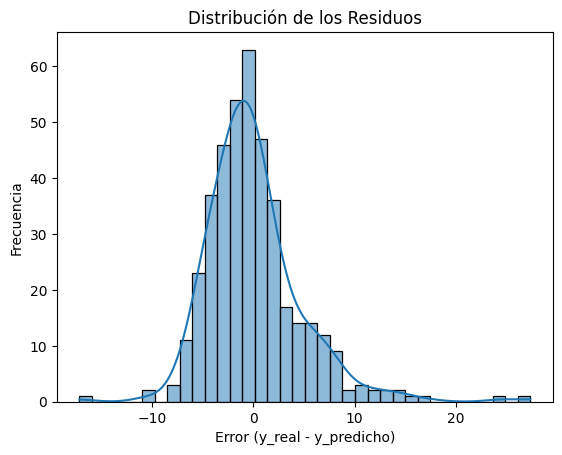

In [ ]:
sns.histplot(residual, kde=True)
plt.title("Distribución de los Residuos")
plt.xlabel("Error (y_real - y_predicho)")
plt.ylabel("Frecuencia")
plt.show()

### Interpretación del Histograma de Residuos

* Distribución: La mayoría de los residuos se agrupan en torno a cero, lo que es deseable en un modelo de regresión. Sin embargo, la distribución no es perfectamente simétrica ni normal; hay una asimetría a la derecha (cola larga hacia valores positivos).

* Curtosis: Presenta una leve curtosis positiva (mayor concentración en el centro y colas más largas), lo que también se observa en los estadísticos Jarque-Bera y Omnibus del resumen del modelo.

* Conclusión: Aunque no hay indicios de errores extremadamente grandes, la no normalidad de los residuos sugiere que las inferencias del modelo (como los intervalos de confianza y pruebas t) deben interpretarse con precaución. Podría considerarse una transformación o el uso de otro modelo si esto afecta los resultados.

In [ ]:
# Función para calcular el R cuadrado ajustado
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# función para calcular MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# Función para calcular diferentes métricas para comprobar el rendimiento de un modelo de regresión.
def model_performance_regression(model, predictors, target):
    """
    Función para calcular diferentes métricas para comprobar el rendimiento del modelo de regresión.

    Modelo: regresor
    Predictores: variables independientes
    Objetivo: variable dependiente
    """

    # predecir utilizando las variables independientes
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # tRMSE
    mae = mean_absolute_error(target, pred)  # MAE
    mape = mape_score(target, pred)  # MAPE

    # creando un marco de datos de métricas
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

# RMSE
def rmse(predictions, targets):
    return np.sqrt(((targets - predictions) ** 2).mean())


# MAPE
def mape(predictions, targets):
    return np.mean(np.abs((targets - predictions)) / targets) * 100


# MAE
def mae(predictions, targets):
    return np.mean(np.abs((targets - predictions)))


# Rendimiento del modelo en datos de prueba y entrenamiento
def model_pref(olsmodel, x_train, x_test, y_train,y_test):

    # Predicción en muestra
    y_pred_train = olsmodel.predict(x_train)
    y_observed_train = y_train

    # Predicción sobre datos de prueba
    y_pred_test = olsmodel.predict(x_test)
    y_observed_test = y_test

    print(
        pd.DataFrame(
            {
                "Data": ["Train", "Test"],
                "RMSE": [
                    rmse(y_pred_train, y_observed_train),
                    rmse(y_pred_test, y_observed_test),
                ],
                "MAE": [
                    mae(y_pred_train, y_observed_train),
                    mae(y_pred_test, y_observed_test),
                ],
                "MAPE": [
                    mape(y_pred_train, y_observed_train),
                    mape(y_pred_test, y_observed_test),
                ],
            }
        )
    )


In [ ]:
# 4. Ajustar X_test con las mismas columnas finales que X_selected
X_test_selected = X_test[X_selected.columns]

# 5. Evaluar el modelo con tu función model_performance_regression
lin_reg_test = model_performance_regression(model, X_test_selected, y_test)
print("\nDesempeño del modelo en el conjunto de prueba:")
print(lin_reg_test)


Desempeño del modelo en el conjunto de prueba:
       RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  5.049774  3.265642   0.652272        0.609772  17.105606


| Métrica            | Valor  | Interpretación                                                                               |
| ------------------ | ------ | -------------------------------------------------------------------------------------------- |
| **RMSE**           | 5.05   | En promedio, las predicciones del modelo se desvían ±5.05 unidades del valor real de `medv`. |
| **MAE**            | 3.27   | El error promedio absoluto entre las predicciones y los valores reales es de 3.27 unidades.  |
| **R-squared**      | 0.652  | El modelo explica aproximadamente el 65.2% de la variabilidad de los precios (`medv`).       |
| **Adj. R-squared** | 0.610  | Valor ajustado por el número de variables; muestra una capacidad explicativa más realista.   |
| **MAPE**           | 17.11% | El modelo tiene un error porcentual promedio del 17.1% en sus predicciones.                  |


In [ ]:
model.params

,0
const,30.931097
crim,-0.108568
chas,2.875249
nox,-17.953929
rm,4.463746
dis,-1.234960
rad,0.238116
tax,-0.007795
ptratio,-1.012242
b,0.012274


In [ ]:
X_test_selected.columns

Index(['const', 'crim', 'chas', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio',
       'b', 'lstat'],
      dtype='object')

In [ ]:
# Creamos X_test_selected con las mismas columnas
X_test_selected = X_test[X_selected.columns]

# Crear y entrenar el modelo de regresión lineal
lr = LinearRegression()
lr.fit(X_selected, y_train)

# Predecir los valores de MEDV para el conjunto de prueba
y_pred = lr.predict(X_test_selected)

In [ ]:
y_pred

array([29.45756601, 35.13238109, 15.0171872 , 25.17039297, 18.75131405,
       23.73548717, 17.99019595, 13.78700254, 23.27946376, 20.72688222,
       25.08152489, 19.56557467, -6.06305796, 22.31025603, 19.62145895,
       26.15686736, 19.61715491,  5.65669501, 39.24107728, 17.62896064,
       26.62424134, 29.07771314, 11.61438275, 23.73525722, 17.76430078,
       15.9429453 , 23.11266536, 14.65776955, 22.80408081, 19.31221462,
       22.88137457, 25.44949928, 25.86246002, 17.59408536, 16.88822972,
       16.86635663, 31.7826268 , 20.28685546, 24.01060858, 24.76328886,
       14.03071479, 31.43349569, 40.64982382, 17.84274742, 27.64339818,
       16.91640593, 14.26040718, 26.04159189, 20.46287645, 30.34314365,
       22.12412296, 34.49814467, 16.26508905, 26.30711164, 39.49778589,
       22.75790612, 18.78167402, 30.63493709, 25.5061471 , 13.4850978 ,
       22.86982716, 29.02693963, 31.56109636, 15.73490124, 20.65772914,
       17.10387618, 20.44791675, 25.7116099 , 28.88955665, 11.61

In [ ]:
X_selected_pred = X_selected.copy()
X_selected_pred['medv'] = y_train
X_selected_pred['pred'] = lr.predict(X_selected)
X_selected_pred['error'] = X_selected_pred['pred'] - X_selected_pred['medv']
X_selected_pred

,const,crim,chas,nox,rm,dis,rad,tax,ptratio,b,lstat,medv,pred,error
477,1.0,15.02340,0,0.6140,5.304,2.1007,24,666,20.2,349.48,24.91,12.0,11.012915,-0.987085
15,1.0,0.62739,0,0.5380,5.834,4.4986,4,307,21.0,395.62,8.47,19.9,19.525864,-0.374136
332,1.0,0.03466,0,0.4379,6.031,6.6407,1,304,16.9,362.25,7.83,19.4,22.997561,3.597561
423,1.0,7.05042,0,0.6140,6.103,2.0218,24,666,20.2,2.52,23.29,13.4,12.110601,-1.289399
19,1.0,0.72580,0,0.5380,5.727,3.7965,4,307,21.0,390.95,11.28,18.2,18.413547,0.213547
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,1.0,0.17120,0,0.5200,5.836,2.2110,5,384,20.9,395.67,18.66,19.5,17.272994,-2.227006
270,1.0,0.29916,0,0.4640,5.856,4.4290,3,223,18.6,388.65,13.00,21.1,21.523421,0.423421
348,1.0,0.01501,0,0.4350,6.635,8.3440,4,280,17.0,390.94,5.99,24.5,25.735537,1.235537
435,1.0,11.16040,0,0.7400,6.629,2.1247,24,666,20.2,109.85,23.27,13.4,12.950586,-0.449414


In [ ]:
selected_features = X_selected.columns.drop("const", errors="ignore").tolist()
selected_features

['crim', 'chas', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat']

In [ ]:
# Modelo base: todas las variables, sin columna const
lr_base = LinearRegression()
lr_base.fit(X_train, y_train)
y_pred_base = lr_base.predict(X_test)

# Modelo con selección hacia atrás: exactamente las columnas elegidas por OLS
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
lr_selected = LinearRegression()
lr_selected.fit(X_train_selected, y_train)
y_pred_selected = lr_selected.predict(X_test_selected)

print("Intercepto (modelo seleccionado):", lr_selected.intercept_)
display(pd.Series(lr_selected.coef_, index=selected_features, name="Coeficiente").to_frame())


def evaluar_regresion(y_real, y_estimado):
    mse = mean_squared_error(y_real, y_estimado)
    return {
        "MAE": mean_absolute_error(y_real, y_estimado),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_estimado)
    }

resultados = pd.DataFrame({
    "Lineal (todas las variables)": evaluar_regresion(y_test, y_pred_base),
    "Lineal (variables seleccionadas)": evaluar_regresion(y_test, y_pred_selected)
}).T
print("Evaluación sobre el conjunto de PRUEBA:")
display(resultados.round(4))

Intercepto (modelo seleccionado): 30.931096918953166


,Coeficiente
crim,-0.108568
chas,2.875249
nox,-17.953929
rm,4.463746
dis,-1.234960
rad,0.238116
tax,-0.007795
ptratio,-1.012242
b,0.012274
lstat,-0.510235


Evaluación sobre el conjunto de PRUEBA:


,MAE,MSE,RMSE,R²
Lineal (todas las variables),3.1891,24.2911,4.9286,0.6688
Lineal (variables seleccionadas),3.2656,25.5002,5.0498,0.6523


### Interpretación de las métricas

**MAE (Error Absoluto Medio)**

$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

Es el promedio de la magnitud absoluta de los errores. Se expresa en **miles de dólares**.

**MSE (Error Cuadrático Medio)**

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

Promedio de los errores cuadrados; penaliza más los errores grandes. Se expresa en **(miles de dólares)²**.

**RMSE (Raíz del Error Cuadrático Medio)**

$$RMSE = \sqrt{MSE}$$

Magnitud de error que da mayor peso a los errores grandes, en **miles de dólares**. No es el promedio aritmético de los errores.

**R² (Coeficiente de determinación)**

$$R^2 = 1 - \frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}$$

Mide el desempeño relativo a predecir la media de los valores reales del conjunto evaluado. En prueba **puede ser negativo**. Para MAE, MSE y RMSE, menor es mejor; para R², mayor es mejor.

**Nota:** los resultados deben interpretarse a partir de la tabla calculada; no se incluyen cifras fijas que puedan quedar desactualizadas.

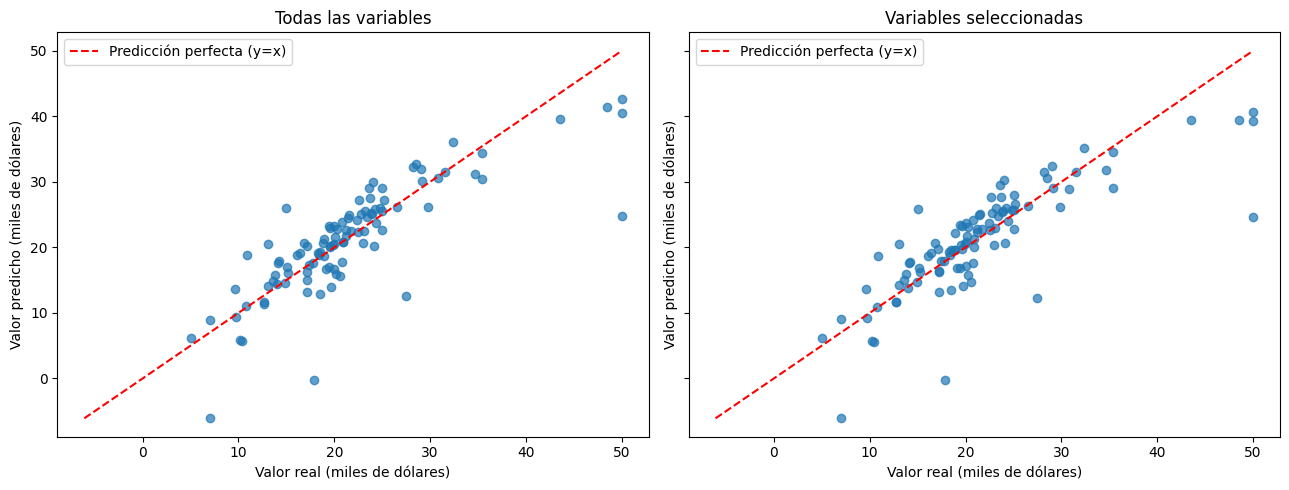

In [ ]:
# Comparación de valores reales frente a predichos: línea de identidad y=x
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
lims = [min(y_test.min(), y_pred_base.min(), y_pred_selected.min()),
        max(y_test.max(), y_pred_base.max(), y_pred_selected.max())]
for ax, pred, title in zip(
    axes,
    [y_pred_base, y_pred_selected],
    ["Todas las variables", "Variables seleccionadas"]
):
    ax.scatter(y_test, pred, alpha=0.7)
    ax.plot(lims, lims, "r--", label="Predicción perfecta (y=x)")
    ax.set_title(title)
    ax.set_xlabel("Valor real (miles de dólares)")
    ax.set_ylabel("Valor predicho (miles de dólares)")
    ax.legend()
plt.tight_layout()
plt.show()

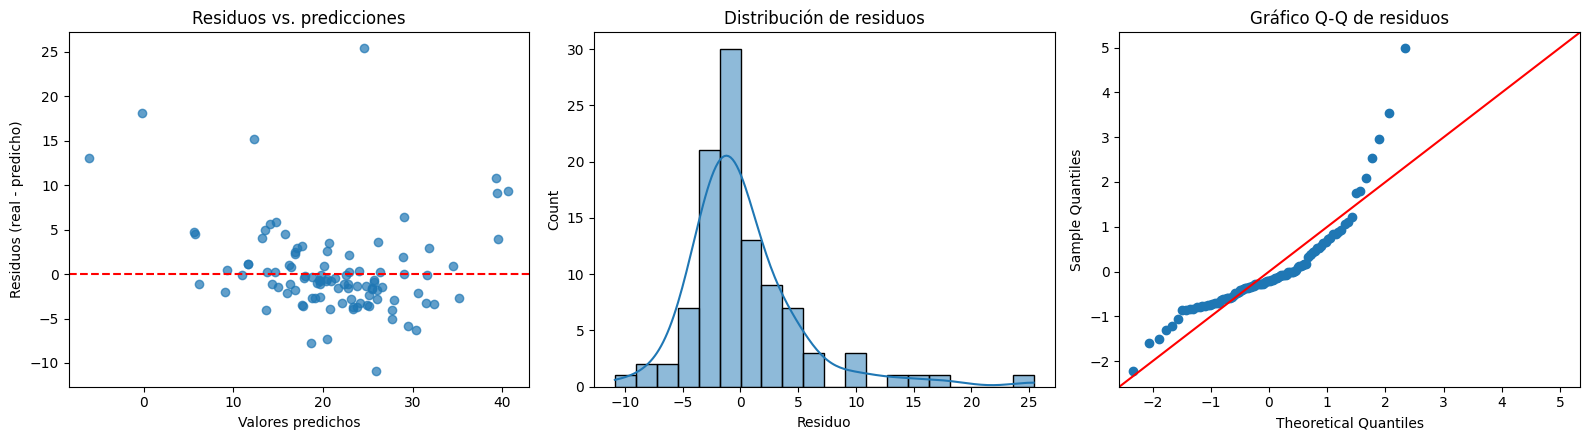

In [ ]:
# Residuo = valor real - valor predicho (modelo seleccionado)
residuos = y_test.to_numpy() - y_pred_selected
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_pred_selected, residuos, alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Valores predichos", ylabel="Residuos (real - predicho)",
            title="Residuos vs. predicciones")
sns.histplot(residuos, kde=True, ax=axes[1])
axes[1].set(title="Distribución de residuos", xlabel="Residuo")
sm.qqplot(residuos, line="45", ax=axes[2], fit=True)
axes[2].set_title("Gráfico Q-Q de residuos")
plt.tight_layout()
plt.show()


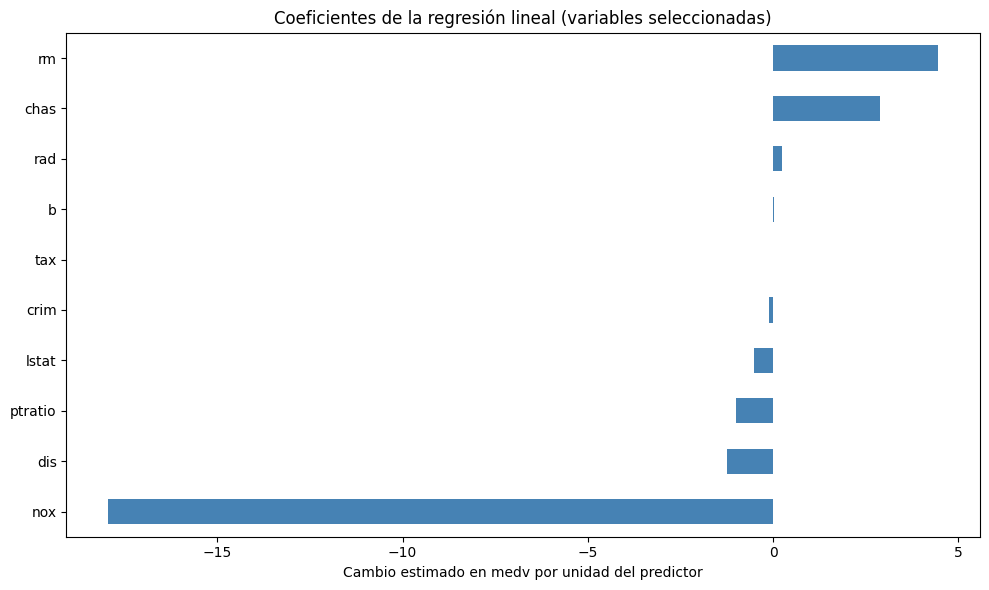

In [ ]:
# Coeficientes: indican dirección y cambio estimado por unidad de cada predictor
# No constituyen un ranking directo de importancia: las escalas son diferentes.
coeficientes = pd.Series(lr_selected.coef_, index=selected_features).sort_values()
coeficientes.plot.barh(figsize=(10, 6), color="steelblue")
plt.title("Coeficientes de la regresión lineal (variables seleccionadas)")
plt.xlabel("Cambio estimado en medv por unidad del predictor")
plt.tight_layout()
plt.show()